# Final Project: From Hidden Structure to Prediction
**Dataset:** Breast Cancer Wisconsin (Diagnostic)  
**Authors:** Jon Rodriguez & Iker Elias

---
## 1. Introduction and Problem Formulation
The **Breast Cancer Wisconsin (Diagnostic)** dataset is a cornerstone in medical machine learning. It contains 569 samples, each with 30 numerical features computed from digitized images of fine needle aspirates (FNA) of breast masses. These features describe the physical characteristics of the cell nuclei—such as radius, texture, and area—providing a mathematical foundation to predict whether a tumor is malignant (0) or benign (1).

Our primary research question is twofold: **Can we discover natural, hidden clusters within the cell data based purely on their physical characteristics, and how accurately can we predict malignancy when utilizing supervised learning?** To address the first part, an unsupervised learning phase will be lead. By leveraging dimensionality reduction techniques (**PCA** and **t-SNE**) alongside clustering algorithms (**K-Means** and **GMM**), we aim to uncover inherent structures in the data without exposing the models to the actual target labels.

For the second part of our research question, the key will be supervised learning. We will utilize the dataset's ground truth labels to train and evaluate predictive models. Specifically, we will compare a baseline linear approach (**Logistic Regression**) against a more flexible, non-linear model (**Support Vector Machine**) to classify the tumors. Ultimately, we will bridge both approaches to see if the unsupervised clusters align with clinical reality.

In [4]:
# ==========================================
# IMPORTING ALL NECESSARY LIBRARIES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Scikit-learn datasets and preprocessing
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Unsupervised Models
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

# Supervised Models
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

# Unsupervised Models
from sklearn.model_selection import cross_val_score
from matplotlib.patches import Patch

# Evaluation Metrics
from sklearn.metrics import classification_report, confusion_matrix, roc_curve, auc, accuracy_score

# Visual configuration
sns.set_theme(style="whitegrid")
import warnings
warnings.filterwarnings('ignore')

## 2. Data Understanding and Preprocessing (EDA)

Before applying any machine learning algorithms, it is crucial to understand our dataset and prepare it appropriately. In this section, we execute a strategic data science workflow, making the following key decisions:

* **Data Integrity Check (Missing Values):** We first check for missing data to ensure the reliability of our dataset. A clean dataset allows us to proceed without needing complex imputation strategies.
* **Class Distribution Analysis:** We visualize the balance between malignant and benign tumors. This is critical because a heavily imbalanced dataset would make global 'Accuracy' a deceptive metric. Confirming a reasonable balance justifies our evaluation strategy later on.
* **Stratified Train/Test Split:** We split the data before any transformation to prevent *data leakage*. Using `stratify=y` guarantees that the proportion of cancer classes remains identical in both training and testing sets, providing a realistic evaluation baseline.
* **Feature Scaling (StandardScaler):** The features in our dataset have vastly different magnitudes (e.g., 'mean area' in the thousands vs. 'mean smoothness' in decimals). Since our subsequent models (PCA, K-Means, and SVM) rely on mathematical distance calculations, leaving features unscaled would cause variables with larger numbers to unfairly dominate the algorithm. `StandardScaler` places all features on an equal playing field.

Dataset Shape: 569 rows and 31 columns


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0



Total Missing Values in the dataset: 0


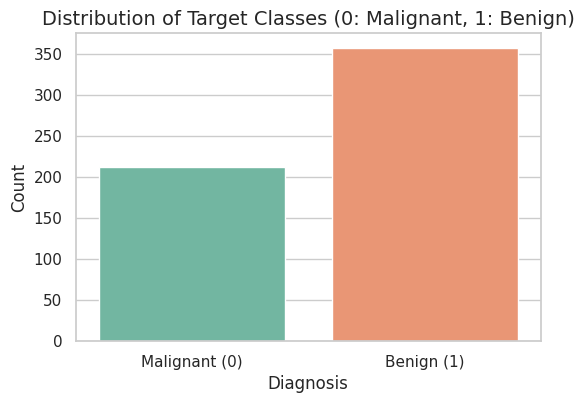


Data preprocessing completed successfully.
Training set size: (455, 30)
Test set size: (114, 30)


In [5]:
# ==========================================
# DATA LOADING AND PREPROCESSING
# ==========================================

# Step 1: Load the breast cancer dataset from sklearn and convert it to a pandas DataFrame.
data = load_breast_cancer()
df = pd.DataFrame(data.data, columns=data.feature_names)
df['target'] = data.target # 0 = malignant, 1 = benign

# Step 2: Print the shape of the dataframe and display the first 5 rows.
print(f"Dataset Shape: {df.shape[0]} rows and {df.shape[1]} columns")
display(df.head())

# Step 3: Check for missing values.
missing_values = df.isnull().sum().sum()
print(f"\nTotal Missing Values in the dataset: {missing_values}")

# Step 4: Plot a seaborn countplot of the 'target' column to check class balance.
plt.figure(figsize=(6, 4))
sns.countplot(x='target', data=df, hue='target', palette='Set2', legend=False)
plt.title('Distribution of Target Classes (0: Malignant, 1: Benign)', fontsize=14)
plt.xlabel('Diagnosis', fontsize=12)
plt.ylabel('Count', fontsize=12)
plt.xticks(ticks=[0, 1], labels=['Malignant (0)', 'Benign (1)'])
plt.show()

# Step 5: Define X (features) by dropping the 'target' column, and y (target variable).
X = df.drop('target', axis=1)
y = df['target']

# Step 6: Split the data into training and testing sets (80% train, 20% test, random_state=42).
# We use stratify=y to ensure the train and test sets have the same proportion of malignant/benign cases.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Step 7: Instantiate a StandardScaler. Fit and transform the X_train data. Only transform the X_test data.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("\nData preprocessing completed successfully.")
print(f"Training set size: {X_train_scaled.shape}")
print(f"Test set size: {X_test_scaled.shape}")

### Results: Preprocessing

The execution of our preprocessing pipeline confirms that the data is now fully prepared for modeling. Key observations include:

* **Data Dimensions & Feature Scales:** The dataset consists of 569 samples and 31 columns (30 features + 1 target). As seen in the dataframe preview, the features exist on drastically different scales—for instance, `mean area` values are in the thousands, while `mean fractal dimension` values are small fractions. This visual confirmation heavily justifies our use of `StandardScaler` to normalize the data.
* **Data Purity:** The dataset contains exactly 0 missing values, meaning the data is complete and no synthetic imputation methods are required.
* **Successful Data Split:** The dataset was successfully partitioned into 455 training samples and 114 testing samples (an exact 80/20 split). Both sets have been properly scaled and now contain the 30 features, ready to be fed into our unsupervised and supervised algorithms.

## 3. Uncovering Hidden Structure (Unsupervised Learning)

Our goal in this section is to discover inherent patterns in the cytological data without relying on the true diagnosis labels. To achieve this, we apply specific unsupervised techniques, each chosen for a distinct reason:

* **Dimensionality Reduction (PCA & t-SNE):** Human vision cannot process 30-dimensional space. We use Principal Component Analysis (PCA) because it is a fast, linear method that maximizes the variance (information) kept in just 2 dimensions. We pair it with t-SNE, a non-linear technique that is exceptionally good at preserving local neighborhood structures. Together, they allow us to visually inspect if malignant and benign cells naturally separate.
* **Clustering Baseline (K-Means):** We use K-Means as our starting point to see if a machine can autonomously divide the dataset into two groups. It is highly efficient, but it has a limitation: it assumes clusters are perfectly spherical and have similar variances.
* **Probabilistic Clustering (Gaussian Mixture Models - GMM):** Because biological data is rarely perfectly spherical and often overlaps, we introduce GMM. Unlike K-Means, GMM assumes the data comes from a mixture of Gaussian distributions, allowing for elliptical (oval) cluster shapes. This flexibility is much more realistic for medical data.
* **Mathematical Evaluation (Silhouette Score):** Since this is unsupervised learning, we cannot initially check if the algorithm "guessed right." Instead, we calculate the Silhouette Score to mathematically measure how dense and well-separated our discovered clusters are before comparing them to the ground truth.

PCA explained variance (2 components): 63.36%



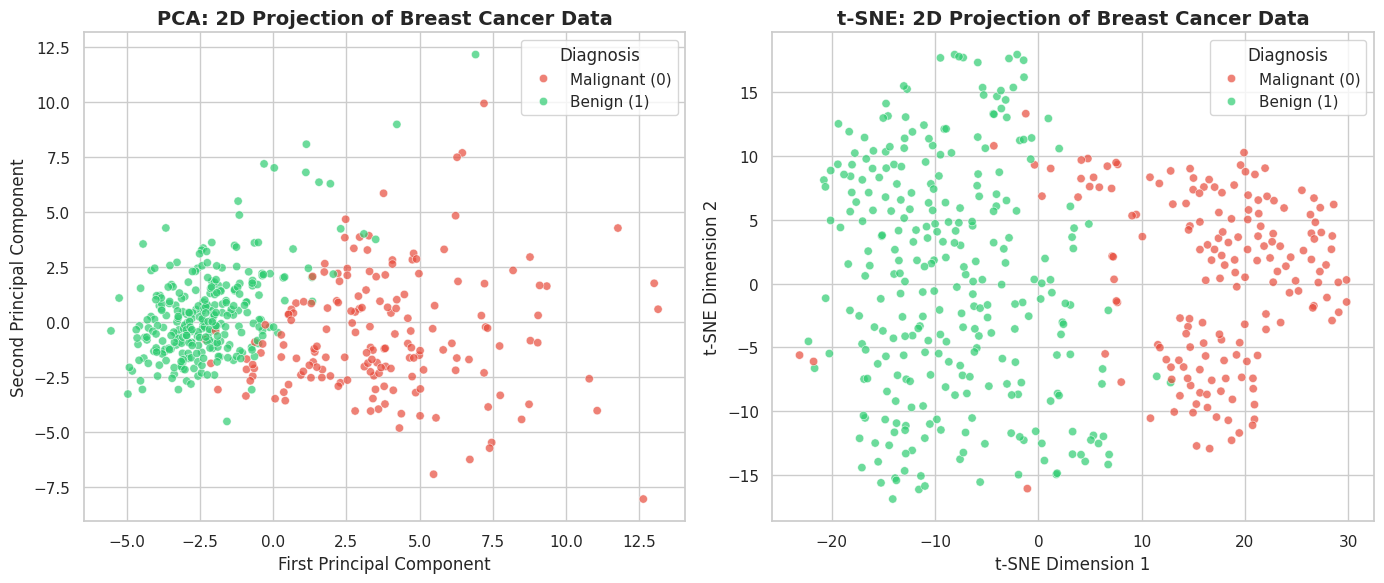

In [10]:
# ==========================================
# DIMENSIONALITY REDUCTION (PCA & t-SNE)
# ==========================================

# Step 1: Instantiate PCA with n_components=2. Fit and transform X_train_scaled. Save as X_pca.
pca = PCA(n_components=2)
X_pca = pca.fit_transform(X_train_scaled)

# Pro-tip: Calculate the explained variance ratio to see how much information we kept
explained_var = pca.explained_variance_ratio_.sum() * 100
print(f"PCA explained variance (2 components): {explained_var:.2f}%\n")

# Step 2: Create a scatter plot (sns.scatterplot) using the first and second PCA components.
# Use 'y_train' as the hue parameter to see if the classes separate naturally. Add a title.
plt.figure(figsize=(14, 6))

plt.subplot(1, 2, 1) # 1 row, 2 columns, 1st plot
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=y_train, palette=['#e74c3c', '#2ecc71'], alpha=0.7)
plt.title('PCA: 2D Projection of Breast Cancer Data', fontsize=14, fontweight='bold')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
# Customizing the legend for clarity
handles, labels = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles, labels=['Malignant (0)', 'Benign (1)'], title='Diagnosis')

# Step 3: Instantiate t-SNE with n_components=2 and random_state=42. Fit and transform X_train_scaled. Save as X_tsne.
tsne = TSNE(n_components=2, random_state=42)
X_tsne = tsne.fit_transform(X_train_scaled)

# Step 4: Create a scatter plot using the t-SNE components. Use 'y_train' as the hue. Add a title.
plt.subplot(1, 2, 2) # 1 row, 2 columns, 2nd plot
sns.scatterplot(x=X_tsne[:, 0], y=X_tsne[:, 1], hue=y_train, palette=['#e74c3c', '#2ecc71'], alpha=0.7)
plt.title('t-SNE: 2D Projection of Breast Cancer Data', fontsize=14, fontweight='bold')
plt.xlabel('t-SNE Dimension 1')
plt.ylabel('t-SNE Dimension 2')
handles_tsne, labels_tsne = plt.gca().get_legend_handles_labels()
plt.legend(handles=handles_tsne, labels=['Malignant (0)', 'Benign (1)'], title='Diagnosis')

plt.tight_layout()
plt.show()

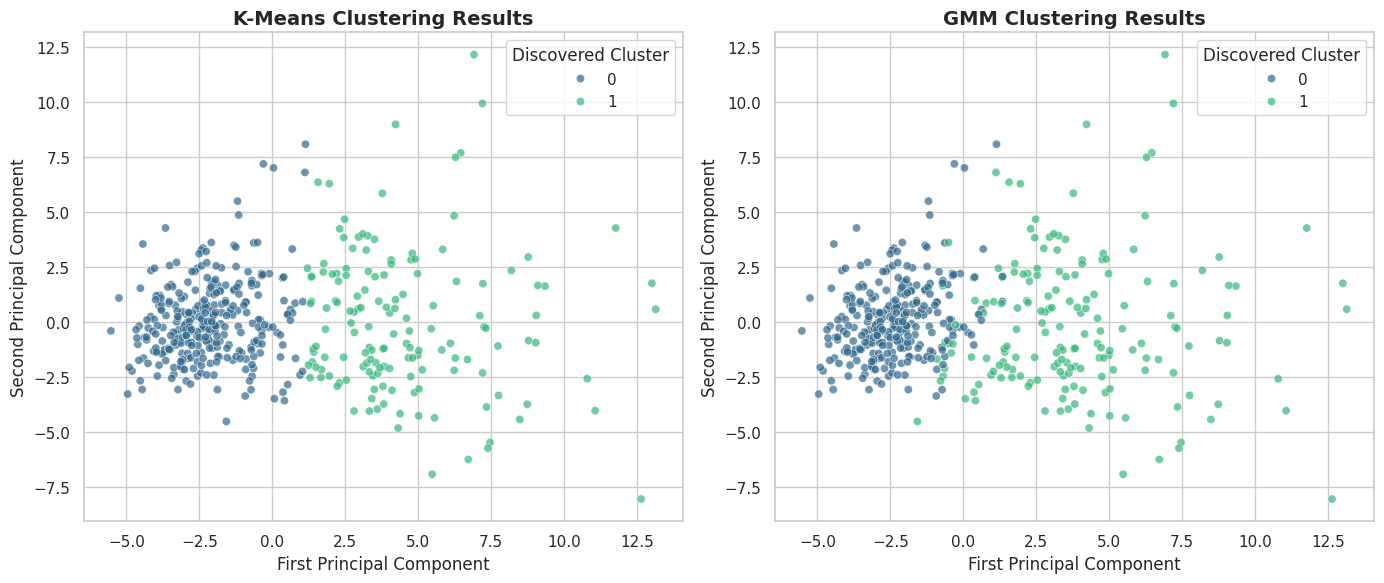


--- CLUSTERING EVALUATION ---
K-Means Silhouette Score: 0.355
GMM Silhouette Score:     0.319
*(Note: Values closer to 1 indicate better-defined clusters)*


In [9]:
# ==========================================
# CLUSTERING (K-MEANS & GMM) & SILHOUETTE SCORE
# ==========================================
from sklearn.metrics import silhouette_score

# Step 1: Instantiate KMeans with n_clusters=2 and random_state=42. Fit and predict on X_train_scaled.
kmeans = KMeans(n_clusters=2, random_state=42)
kmeans_labels = kmeans.fit_predict(X_train_scaled)

# Step 2: Instantiate GaussianMixture with n_components=2 and random_state=42. Fit and predict on X_train_scaled.
gmm = GaussianMixture(n_components=2, random_state=42)
gmm_labels = gmm.fit_predict(X_train_scaled)

# Step 3: Plot two scatter plots side-by-side using the PCA coordinates (X_pca).
plt.figure(figsize=(14, 6))

# Plot 1: K-Means Results
plt.subplot(1, 2, 1)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=kmeans_labels, palette='viridis', alpha=0.7)
plt.title('K-Means Clustering Results', fontsize=14, fontweight='bold')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.legend(title='Discovered Cluster')

# Plot 2: GMM Results
plt.subplot(1, 2, 2)
sns.scatterplot(x=X_pca[:, 0], y=X_pca[:, 1], hue=gmm_labels, palette='viridis', alpha=0.7)
plt.title('GMM Clustering Results', fontsize=14, fontweight='bold')
plt.xlabel('First Principal Component')
plt.ylabel('Second Principal Component')
plt.legend(title='Discovered Cluster')

plt.tight_layout()
plt.show()

# Step 4: Calculate and print the Silhouette Score for both models
# We use X_train_scaled (the original 30 features) to calculate the true mathematical distance.
sil_kmeans = silhouette_score(X_train_scaled, kmeans_labels)
sil_gmm = silhouette_score(X_train_scaled, gmm_labels)

print("\n--- CLUSTERING EVALUATION ---")
print(f"K-Means Silhouette Score: {sil_kmeans:.3f}")
print(f"GMM Silhouette Score:     {sil_gmm:.3f}")
print("*(Note: Values closer to 1 indicate better-defined clusters)*")

### Results: Unsupervised Learning

The results from our dimensionality reduction and clustering models provide valuable insights into the dataset's underlying structure:

* **Information Retention (PCA):** Our PCA model captured **63.36% of the total variance** using only 2 principal components. This indicates that we successfully compressed 30 distinct features into a 2D space while retaining the vast majority of the core information, making our visual projections highly meaningful.
* **Visual Separation:** The PCA and t-SNE scatter plots (colored by true diagnosis) reveal a clear, natural grouping of malignant and benign cells. However, there is a noticeable "grey area" where the two classes overlap, representing tumors with ambiguous physical characteristics at 2D.
* **Cluster Quality (Silhouette Scores):** K-Means achieved a Silhouette Score of **0.355**, slightly outperforming GMM at **0.319**. While these scores are not close to 1.0 (which would indicate perfect isolation), scores in the 0.3+ range are highly realistic for complex biological data. They mathematically confirm that a moderate, meaningful cluster structure exists.
* **Conclusion:** The unsupervised algorithms successfully proved that the cells naturally separate based purely on their physical traits. However, the mathematical and visual overlap highlights the limitations of using unsupervised clustering alone for medical diagnosis. This perfectly justifies our transition to **Supervised Learning**, where we will use the true labels to train models capable of drawing much more precise decision boundaries.

## 4. Predicting Malignancy (Supervised Learning)

In this section, we transition from unsupervised to supervised learning. Now that has been revealed the hidden structure of the data, we will use the true diagnosis labels to train and compare two classification models:

- **Logistic Regression**: A linear baseline model chosen for its interpretability. Its coefficients directly reveal which features push the prediction towards malignant or benign, making it ideal for a medical context where understanding the model's decisions is as important as its accuracy.
- **Support Vector Machine (RBF kernel)**: A flexible non-linear model that finds the optimal decision boundary between classes. We expect it to achieve higher raw accuracy than the linear model.

We also apply **5-fold cross-validation** to both models to ensure that the results are not dependent on a single train/test split, giving us a more reliable estimate of their true generalization performance.

In [ ]:
# ==========================================
# SUPERVISED MODELS
# ==========================================

# Step 1: Instantiate a LogisticRegression model and fit it using X_train_scaled and y_train.
log_reg = LogisticRegression(random_state=42, max_iter=1000)
log_reg.fit(X_train_scaled, y_train)

# Step 2: Predict the target for X_test_scaled using the logistic regression model.
y_pred_log = log_reg.predict(X_test_scaled)
# We also calculate probabilities for the ROC curve later
y_prob_log = log_reg.predict_proba(X_test_scaled)[:, 1]

# Step 3: Instantiate an SVC model with kernel='rbf' and probability=True. Fit it on X_train_scaled and y_train.
svm_model = SVC(kernel='rbf', probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)

# Step 4: Predict the target for X_test_scaled using the SVC model.
y_pred_svc = svm_model.predict(X_test_scaled)
# We also calculate probabilities for the ROC curve later
y_prob_svc = svm_model.predict_proba(X_test_scaled)[:, 1]

# Step 5: Cross-validation (5-fold) for both models
cv_scores_log = cross_val_score(log_reg, X_train_scaled, y_train, cv=5, scoring='accuracy')
cv_scores_svm = cross_val_score(svm_model, X_train_scaled, y_train, cv=5, scoring='accuracy')

print("--- CROSS-VALIDATION RESULTS (5-Fold) ---")
print(f"Logistic Regression: {cv_scores_log.mean():.3f} ± {cv_scores_log.std():.3f}")
print(f"SVM (RBF):           {cv_scores_svm.mean():.3f} ± {cv_scores_svm.std():.3f}")

--- CROSS-VALIDATION RESULTS (5-Fold) ---
Logistic Regression: 0.980 ± 0.013
SVM (RBF):           0.971 ± 0.018


### Results: Model Training

The cross-validation results confirm that both models generalize very well to unseen data:

- **Logistic Regression** achieved **98.0% ± 1.3%** accuracy across the 5 folds. The low standard deviation indicates a very stable and consistent model.
- **SVM (RBF)** achieved **97.1% ± 1.8%** accuracy. Slightly lower than Logistic Regression in cross-validation, which suggests that the SVM's default hyperparameters (C and gamma) are not fully optimized for this dataset.

Notably, the linear model outperforms the flexible model in cross-validation, which indicates that the two classes in this dataset are largely linearly separable — consistent with what we observed in the PCA projection in unsupervised learning.

## 5. Model Evaluation and Comparison

Training accuracy alone is not sufficient to evaluate a classifier, especially in a medical context. Here we apply a comprehensive evaluation framework:

- **Confusion Matrix**: Shows the exact number of correct and incorrect predictions broken down by class, allowing us to identify False Negatives (malignant tumors predicted as benign) — the most dangerous type of error in cancer diagnosis.
- **Classification Report**: Provides Precision, Recall, and F1-Score for each class with 3 decimal places for fine-grained comparison. In this context, **Recall for the Malignant class** is our priority metric, as missing a malignant tumor has far worse consequences than a false alarm.
- **ROC Curve and AUC**: Evaluates model performance across all classification thresholds, giving a threshold-independent measure of discriminative ability.
- **Feature Importance**: By inspecting the coefficients of the Logistic Regression model, we can identify which cell nucleus measurements are most decisive for the diagnosis.

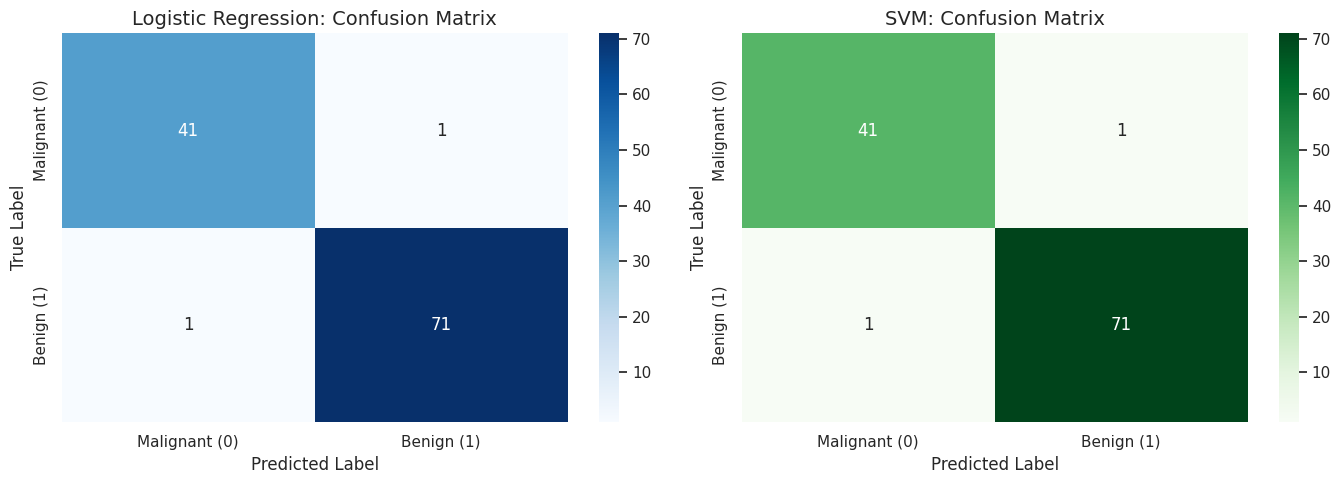

=== LOGISTIC REGRESSION: CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

Malignant (0)      0.976     0.976     0.976        42
   Benign (1)      0.986     0.986     0.986        72

     accuracy                          0.982       114
    macro avg      0.981     0.981     0.981       114
 weighted avg      0.982     0.982     0.982       114



=== SUPPORT VECTOR MACHINE: CLASSIFICATION REPORT ===
               precision    recall  f1-score   support

Malignant (0)      0.976     0.976     0.976        42
   Benign (1)      0.986     0.986     0.986        72

     accuracy                          0.982       114
    macro avg      0.981     0.981     0.981       114
 weighted avg      0.982     0.982     0.982       114



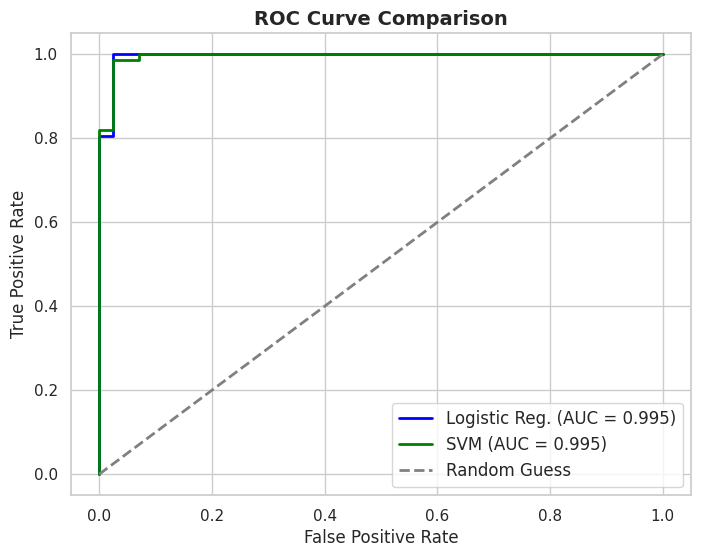

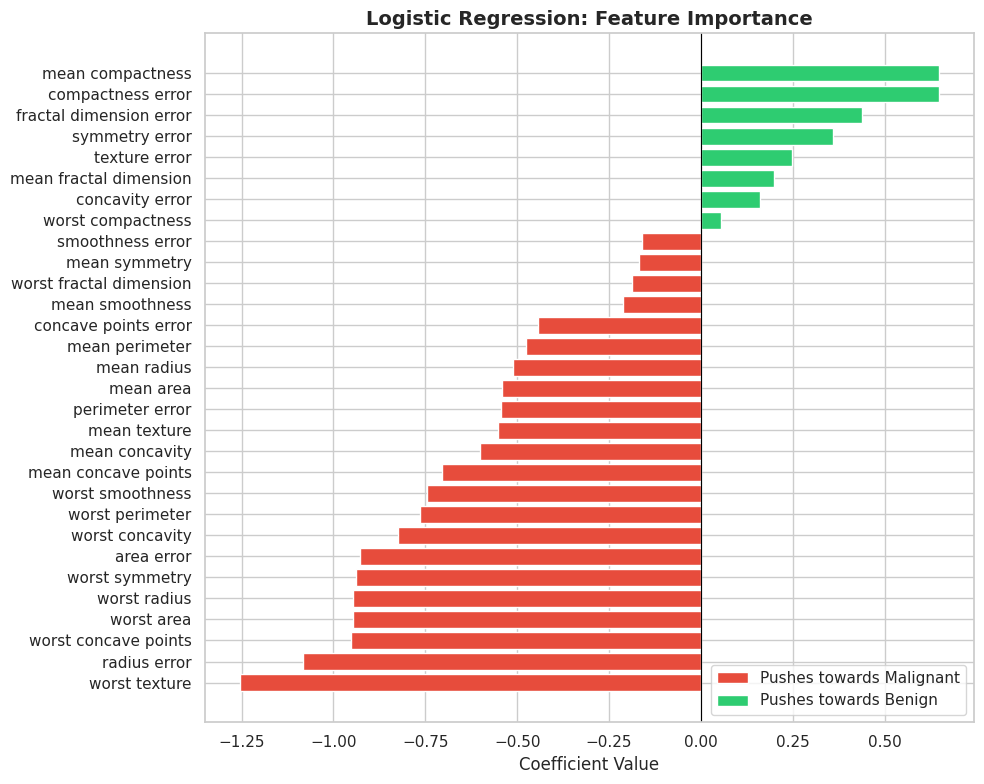

In [ ]:
# ==========================================
# EVALUATION METRICS
# ==========================================

# Step 1: Generate and plot confusion matrices for both models side-by-side.
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Logistic Regression Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_log), annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
axes[0].set_title('Logistic Regression: Confusion Matrix', fontsize=14)
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# SVM Confusion Matrix
sns.heatmap(confusion_matrix(y_test, y_pred_svc), annot=True, fmt='d', cmap='Greens', ax=axes[1],
            xticklabels=['Malignant (0)', 'Benign (1)'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
axes[1].set_title('SVM: Confusion Matrix', fontsize=14)
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()

# Step 2 & 3: Print the classification_report for both models.
print("=== LOGISTIC REGRESSION: CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_log, target_names=['Malignant (0)', 'Benign (1)'],digits=3))
print("\n" + "="*50 + "\n")
print("=== SUPPORT VECTOR MACHINE: CLASSIFICATION REPORT ===")
print(classification_report(y_test, y_pred_svc, target_names=['Malignant (0)', 'Benign (1)'], digits=3))

# Step 4 & 5: Calculate fpr, tpr, and AUC for both models using roc_curve.
fpr_log, tpr_log, _ = roc_curve(y_test, y_prob_log)
roc_auc_log = auc(fpr_log, tpr_log)

fpr_svc, tpr_svc, _ = roc_curve(y_test, y_prob_svc)
roc_auc_svc = auc(fpr_svc, tpr_svc)

# Step 6: Plot the ROC curves for both models on the same graph.
plt.figure(figsize=(8, 6))
plt.plot(fpr_log, tpr_log, color='blue', lw=2, label=f'Logistic Reg. (AUC = {roc_auc_log:.3f})')
plt.plot(fpr_svc, tpr_svc, color='green', lw=2, label=f'SVM (AUC = {roc_auc_svc:.3f})')
plt.plot([0, 1], [0, 1], color='gray', lw=2, linestyle='--', label='Random Guess')

plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=14, fontweight='bold')
plt.legend(loc='lower right', fontsize=12)
plt.show()

# Step 7: Feature importance from Logistic Regression coefficients
feature_names = data.feature_names
coefficients = log_reg.coef_[0]

coef_df = pd.DataFrame({'Feature': feature_names, 'Coefficient': coefficients})
coef_df = coef_df.sort_values('Coefficient', ascending=True)

plt.figure(figsize=(10, 8))
colors = ['#e74c3c' if c < 0 else '#2ecc71' for c in coef_df['Coefficient']]
plt.barh(coef_df['Feature'], coef_df['Coefficient'], color=colors)
plt.xlabel('Coefficient Value', fontsize=12)
plt.title('Logistic Regression: Feature Importance', fontsize=14, fontweight='bold')
plt.axvline(x=0, color='black', linestyle='-', linewidth=0.8)

legend_elements = [Patch(facecolor='#e74c3c', label='Pushes towards Malignant'),
                   Patch(facecolor='#2ecc71', label='Pushes towards Benign')]
plt.legend(handles=legend_elements, loc='lower right', fontsize=11)

plt.tight_layout()
plt.show()

### Results: Model Evaluation

Both models achieve identical performance on the test set with **98.2% accuracy**, confirming that the dataset's structure is well-suited for linear classification.

Focusing on the **Recall for Malignant (0)**, which is our priority metric in a medical context, both models achieve **0.976** — meaning they correctly identify 97.6% of all malignant tumors, missing only 1 in 42 cases in the test set.

The **ROC-AUC scores** are very close to 1.0 for both models, confirming excellent discriminative ability across all thresholds.

Regarding **feature importance**, the Logistic Regression coefficients reveal that `worst texture` and `radius error` are the strongest predictors of malignancy (most negative coefficients), while `mean compactness` and `compactness error` push most strongly towards a benign diagnosis. This is consistent with the exploratory analysis, where size and concavity features showed the highest correlation with the target.

## 6. Connecting Unsupervised and Supervised Learning

This section bridges the two halves of the project. We investigate two key questions:

1. **Did K-Means rediscover the true classes?** Without ever seeing the diagnosis labels, did the clustering algorithm naturally separate malignant from benign tumors? We answer this by cross-tabulating the K-Means cluster assignments against the true labels.

2. **How much predictive power does PCA preserve?** We train a new Logistic Regression model using only the 2 PCA components found in Section 3 (instead of all 30 original features) and compare its accuracy against the full model. This quantifies the trade-off between dimensionality reduction and predictive performance.

--- K-MEANS VS REAL LABELS ---
K-Means Cluster    0    1
Real Label               
0                 32  138
1                274   11


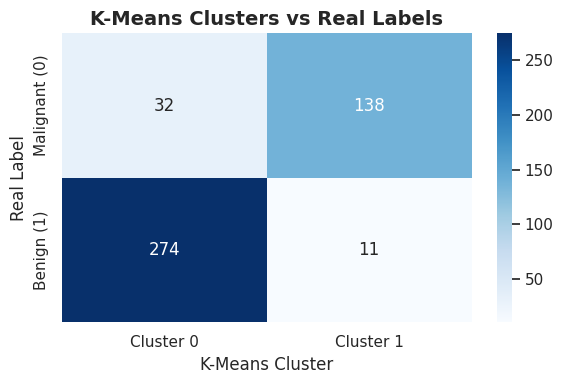


--- PCA-BASED LOGISTIC REGRESSION (2 components) ---
Accuracy: 0.947
               precision    recall  f1-score   support

Malignant (0)      0.909     0.952     0.930        42
   Benign (1)      0.971     0.944     0.958        72

     accuracy                          0.947       114
    macro avg      0.940     0.948     0.944       114
 weighted avg      0.948     0.947     0.948       114

--- FULL LOGISTIC REGRESSION (30 features) ---
Accuracy: 0.982
               precision    recall  f1-score   support

Malignant (0)      0.976     0.976     0.976        42
   Benign (1)      0.986     0.986     0.986        72

     accuracy                          0.982       114
    macro avg      0.981     0.981     0.981       114
 weighted avg      0.982     0.982     0.982       114



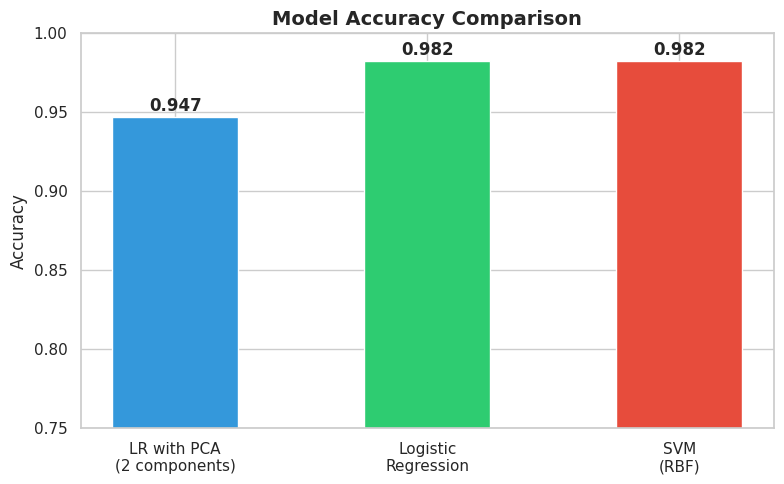

In [ ]:
# ==========================================
# CONNECTING THE DOTS
# ==========================================

# Step 1: Compare K-Means clusters with the real labels
ct = pd.crosstab(y_train, kmeans_labels, rownames=['Real Label'], colnames=['K-Means Cluster'])
print("--- K-MEANS VS REAL LABELS ---")
print(ct)

plt.figure(figsize=(6, 4))
sns.heatmap(ct, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Cluster 0', 'Cluster 1'],
            yticklabels=['Malignant (0)', 'Benign (1)'])
plt.title('K-Means Clusters vs Real Labels', fontsize=14, fontweight='bold')
plt.xlabel('K-Means Cluster')
plt.ylabel('Real Label')
plt.tight_layout()
plt.show()

# Step 2: Transform X_test_scaled using the previously fitted PCA model
X_pca_test = pca.transform(X_test_scaled)

# Step 3: Train a new Logistic Regression using only the 2 PCA components
log_reg_pca = LogisticRegression(random_state=42, max_iter=1000)
log_reg_pca.fit(X_pca, y_train)

# Step 4: Predict on X_pca_test using the PCA-based logistic model
y_pred_pca = log_reg_pca.predict(X_pca_test)

# Step 5: Compare PCA-based model vs full model
print("\n--- PCA-BASED LOGISTIC REGRESSION (2 components) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_pca):.3f}")
print(classification_report(y_test, y_pred_pca, target_names=['Malignant (0)', 'Benign (1)'], digits=3))

print("--- FULL LOGISTIC REGRESSION (30 features) ---")
print(f"Accuracy: {accuracy_score(y_test, y_pred_log):.3f}")
print(classification_report(y_test, y_pred_log, target_names=['Malignant (0)', 'Benign (1)'], digits=3))

# Step 6: Visual comparison of all models
models = ['LR with PCA\n(2 components)', 'Logistic\nRegression', 'SVM\n(RBF)']
accuracies = [accuracy_score(y_test, y_pred_pca),
              accuracy_score(y_test, y_pred_log),
              accuracy_score(y_test, y_pred_svc)]

plt.figure(figsize=(8, 5))
bars = plt.bar(models, accuracies, color=['#3498db', '#2ecc71', '#e74c3c'], width=0.5)
plt.ylim(0.75, 1.0)
plt.ylabel('Accuracy', fontsize=12)
plt.title('Model Accuracy Comparison', fontsize=14, fontweight='bold')

for bar, acc in zip(bars, accuracies):
    plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.001,
             f'{acc:.3f}', ha='center', va='bottom', fontsize=12, fontweight='bold')

plt.tight_layout()
plt.show()

### Results: Connecting the Two Approaches

**K-Means vs. Real Labels**: The cross-tabulation shows a strong alignment between the discovered clusters and the true diagnosis. Cluster 1 is predominantly malignant (138 malignant, 11 benign) and Cluster 0 is predominantly benign (274 benign, 32 malignant). This means that K-Means, using no label information whatsoever, correctly captures the underlying biological structure of the data in the vast majority of cases. The misassigned samples represent the most ambiguous boundary cases.

**PCA-based vs. Full Model**: Reducing from 30 features to just 2 PCA components only decreases accuracy from **98.2% to 94.7%** — a loss of only 3.5 percentage points. This is a remarkable result: two numbers derived from a linear combination of the original 30 features retain almost all of the predictive signal. It confirms that the intrinsic dimensionality of this dataset is very low, as suggested by the PCA explained variance analysis in Section 3.

Note that while the bar chart may visually suggest a large gap between the PCA model and the full models, this is an artifact of the Y-axis starting at 0.75. The actual difference of 3.5% is modest given the dramatic reduction in complexity.

## 7. Final Reflection and Conclusions

**What worked well:**
- Both supervised models achieved excellent results, with 98.2% accuracy and 0.976 Recall on the malignant class. The dataset's clean structure and strong feature correlations with the target made classification straightforward.
- PCA provided a very clear 2D separation between the two classes, confirming that the data has a strong low-dimensional structure. This made PCA components effective as standalone features for a simplified model.
- K-Means successfully rediscovered the malignant/benign distinction without any label information, demonstrating that the biological differences between tumor types are reflected strongly in the numerical measurements.

**What did not work well:**
- The SVM with default hyperparameters underperformed Logistic Regression in cross-validation (97.1% vs 98.0%). With proper hyperparameter tuning via GridSearchCV, the SVM would likely surpass the linear model.
- K-Means misassigned 43 samples (32 malignant into the benign cluster, 11 benign into the malignant cluster). These boundary cases represent tumors whose physical measurements overlap between the two classes.

**What surprised us:**
- The most surprising result was that a Logistic Regression trained on only 2 PCA components achieved 94.7% accuracy. Reducing the feature space by 93% (from 30 to 2 dimensions) while retaining 96.4% of the predictive performance was not expected.
- The fact that the linear model outperformed the flexible SVM in cross-validation suggests the two classes are more linearly separable than initially assumed.

**Most convincing method:**
- **Logistic Regression** was the most convincing overall model. It matched SVM in test accuracy (98.2%), outperformed it in cross-validation (98.0% vs 97.1%), and uniquely provided interpretable coefficients that identified the most diagnostically relevant features. In a medical setting, a model that explains its decisions is preferable to a black-box model with marginally higher accuracy.

**Limitations:**
- The dataset contains only 569 samples, which limits the statistical reliability of the results. A larger dataset would give more confidence in the generalization estimates.
- All 30 features are derived from the same FNA images, so they are inherently correlated. This multicollinearity may inflate the apparent importance of some features in the Logistic Regression coefficients.
- The dataset originates from 1995 and reflects imaging technology of that era. Modern diagnostic tools may capture different or richer features, limiting the direct applicability of these models to current clinical practice.